<a href="https://colab.research.google.com/github/Kamal-03A/Ml-ops-2027/blob/main/IMDB_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import pickle

import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [ ]:
df = pd.read_csv("IMDB Dataset.csv")

print(df.head())
print(df.shape)

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
(50000, 2)


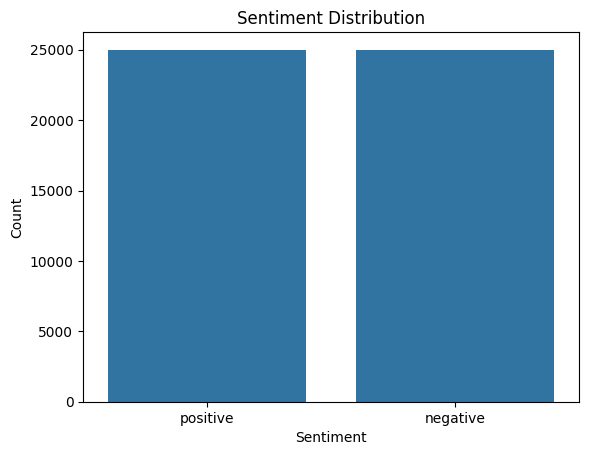

In [ ]:
sns.countplot(x=df['sentiment'])

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")

plt.show()

In [ ]:
reviews = df['review']
sentiments = df['sentiment']

encoder = LabelEncoder()
labels = encoder.fit_transform(sentiments)

tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(reviews)

sequences = tokenizer.texts_to_sequences(reviews)

padded = pad_sequences(sequences, maxlen=200)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    padded,
    labels,
    test_size=0.2,
    random_state=42
)

In [ ]:
model = Sequential([
    Embedding(10000, 100, input_length=200),
    LSTM(64),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=64,
    validation_data=(X_test, y_test)
)

Epoch 1/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 159s 251ms/step - accuracy: 0.8082 - loss: 0.4179 - val_accuracy: 0.8337 - val_loss: 0.3623
Epoch 2/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 148s 237ms/step - accuracy: 0.9011 - loss: 0.2612 - val_accuracy: 0.8944 - val_loss: 0.2621
Epoch 3/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 149s 238ms/step - accuracy: 0.9230 - loss: 0.2084 - val_accuracy: 0.8753 - val_loss: 0.3583


In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Loss:", loss)
print("Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.8753 - loss: 0.3583
Loss: 0.358314573764801
Accuracy: 0.8752999901771545


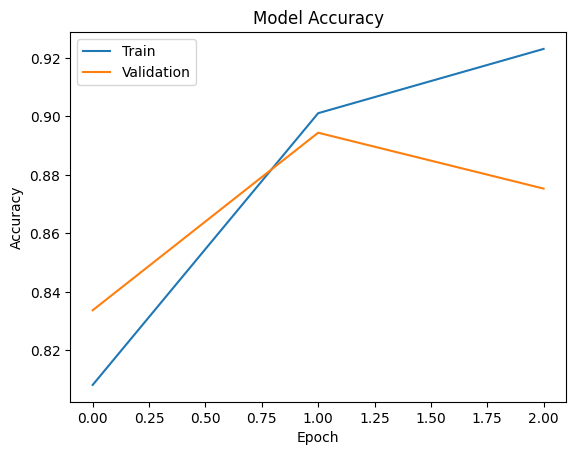

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')

plt.legend(['Train', 'Validation'])

plt.show()

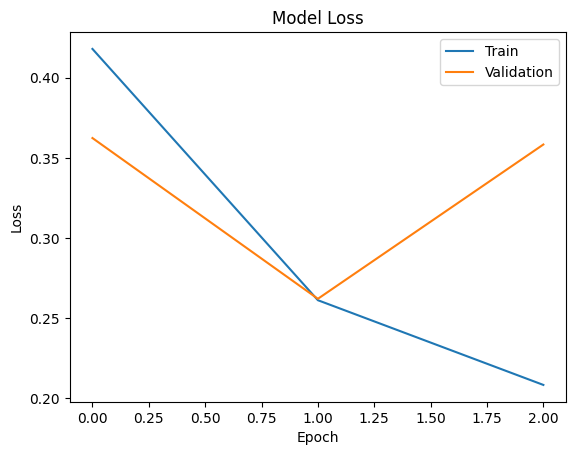

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')

plt.legend(['Train', 'Validation'])

plt.show()

In [ ]:
def predict_review(text):
    sequence = tokenizer.texts_to_sequences([text])
    padded_text = pad_sequences(sequence, maxlen=200)

    prediction = model.predict(padded_text)[0][0]

    if prediction >= 0.5:
        return f"Positive Review ✅\nConfidence: {prediction:.2f}"
    else:
        return f"Negative Review ❌\nConfidence: {1 - prediction:.2f}"

In [ ]:
import gradio as gr

demo = gr.Interface(
    fn=predict_review,
    inputs=gr.Textbox(lines=5, placeholder="Write a movie review here..."),
    outputs="text",
    title="IMDB Sentiment Analysis",
    description="Enter a movie review and the model will classify it as Positive or Negative."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://36fb74b0905404ae8e.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
